# Text classification: six Fakeddit post types from the title

Each Reddit post title is put into one of Fakeddit's six classes: **true**, **satire/parody**, **misleading content**, **imposter content**, **false connection** and **manipulated content**. Only the title text is used, no engagement numbers and no image.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikus iskart saugom ataskaitai
MODEL_PATH = Path("../models/logreg_6way.joblib")
CLASSES = ["true", "satire/parody", "misleading content", "imposter content", "false connection", "manipulated content"]  # 6_way_label 0-5 eiles tvarka

## 1. Load data
The official Fakeddit splits. `subreddit` is loaded only to explain the labels and group the results; the model never sees it.

In [2]:
COLS = ["clean_title", "subreddit", "6_way_label"]
load = lambda name: pd.read_csv(DATA / f"multimodal_{name}.tsv", sep="\t", usecols=COLS)
train, val, test = load("train"), load("validate"), load("test_public")
for df in (train, val, test):
    df["type"] = pd.Categorical(df["6_way_label"].map(dict(enumerate(CLASSES))), categories=CLASSES)  # skaiciu paverciam pavadinimu, kad lenteles butu skaitomos
train.shape, val.shape, test.shape

((564000, 4), (59342, 4), (59319, 4))

## 2. Exploration

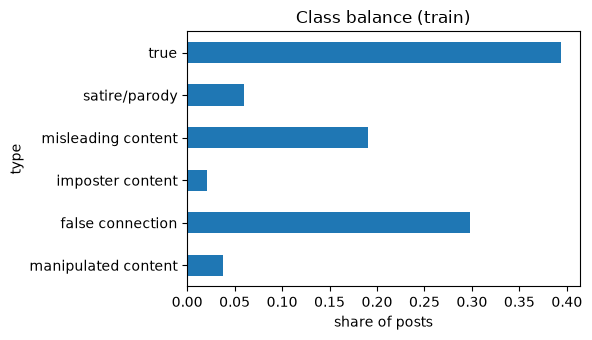

type
true                   0.394
satire/parody          0.059
misleading content     0.190
imposter content       0.021
false connection       0.298
manipulated content    0.038
Name: proportion, dtype: float64

In [3]:
share = train["type"].value_counts(normalize=True).reindex(CLASSES)
ax = share.plot.barh(figsize=(6, 3.5), title="Class balance (train)")
ax.invert_yaxis(); ax.set_xlabel("share of posts")
plt.tight_layout(); plt.savefig(FIG / "txt_class_balance.png", dpi=120); plt.show()
share.round(3)

In [4]:
sub = train.groupby("subreddit").agg(type=("type", "first"), labels=("6_way_label", "nunique"), posts=("type", "size"))  # labels = kiek skirtingu klasiu turi subreddit
print("Subreddits with more than one label:", (sub["labels"] > 1).sum())
sub.drop(columns="labels").sort_values(["type", "posts"], ascending=[True, False])

Subreddits with more than one label: 0


,type,posts
subreddit,,
mildlyinteresting,true,86237
photoshopbattles,true,55198
nottheonion,true,31977
upliftingnews,true,23960
neutralnews,true,7512
usnews,true,5941
usanews,true,5875
pic,true,5381
fakealbumcovers,satire/parody,21725


Every subreddit has exactly one label, because Fakeddit labels posts by the subreddit they come from. Some classes are a single subreddit (false connection is only `psbattle_artwork`), so the model in practice learns how each group of subreddits writes titles. Holding out whole subreddits for testing is not possible here, since a class with one subreddit would then have no training data.

In [5]:
train["title_words"] = train["clean_title"].str.split().str.len()
train.groupby("type", observed=True)["title_words"].describe().round(1)  # ar klases skiriasi antrasciu ilgiu

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
true,222081.0,9.5,5.6,1.0,6.0,9.0,12.0,66.0
satire/parody,33481.0,7.6,5.5,1.0,4.0,6.0,10.0,56.0
misleading content,107221.0,7.2,4.7,1.0,4.0,6.0,9.0,58.0
imposter content,11784.0,14.6,6.4,1.0,10.0,14.0,18.0,61.0
false connection,167857.0,4.0,3.8,1.0,2.0,3.0,5.0,553.0
manipulated content,21576.0,11.2,6.2,1.0,7.0,10.0,14.0,54.0


## 3. Features and model
* Input: `clean_title` only.
* TF-IDF on words and word pairs, the same settings as the binary model in `01_ml_model.ipynb`.
* Multinomial logistic regression with `class_weight="balanced"`, so the small classes (imposter 2%, manipulated 4%) are not ignored.

Training takes a few minutes, so the fitted pipeline is saved to `models/logreg_6way.joblib` and loaded on later runs (delete the file to retrain).

In [6]:
if MODEL_PATH.exists():
    model = joblib.load(MODEL_PATH)  # jau ismokytas, nemokom is naujo
else:
    model = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True, stop_words="english"),  # tie patys nustatymai kaip pirmame darbe, kad galetume palyginti
        LogisticRegression(class_weight="balanced", max_iter=1000),  # balanced: reti tipai gauna didesni svori, kitaip modelis juos tiesiog praleistu
    )
    model.fit(train["clean_title"], train["6_way_label"])
    joblib.dump(model, MODEL_PATH)
print("Vocabulary size:", len(model[0].vocabulary_))

Vocabulary size: 50000


## 4. Evaluate
Macro F1 is the main score: it averages the six classes equally, so a model that only gets the big classes right scores low. The majority baseline always answers "true".

In [7]:
rows = {}
for name, df in [("validation", val), ("test", test)]:
    pred = model.predict(df["clean_title"])
    y = df["6_way_label"]
    rows[(name, "baseline")] = {"accuracy": (y == 0).mean(), "macro F1": f1_score(y, np.zeros_like(y), average="macro")}
    rows[(name, "model")] = {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro")}
test["pred"] = pred  # paskutinis ciklo zingsnis yra testas
pd.DataFrame(rows).T.round(4)

accuracy  macro F1
validation baseline    0.3930    0.0940
           model       0.6297    0.5221
test       baseline    0.3963    0.0946
           model       0.6351    0.5285

In [8]:
print(classification_report(test["6_way_label"], test["pred"], target_names=CLASSES, digits=4))  # precision: kiek spejimu teisingi; recall: kiek tos klases irasu rasta

                     precision    recall  f1-score   support

               true     0.8130    0.6321    0.7112     23507
      satire/parody     0.2904    0.5387    0.3774      3514
 misleading content     0.6084    0.5862    0.5971     11297
   imposter content     0.1320    0.4608    0.2052      1224
   false connection     0.7704    0.6916    0.7289     17472
manipulated content     0.4483    0.7163    0.5514      2305

           accuracy                         0.6351     59319
          macro avg     0.5104    0.6043    0.5285     59319
       weighted avg     0.7023    0.6351    0.6582     59319



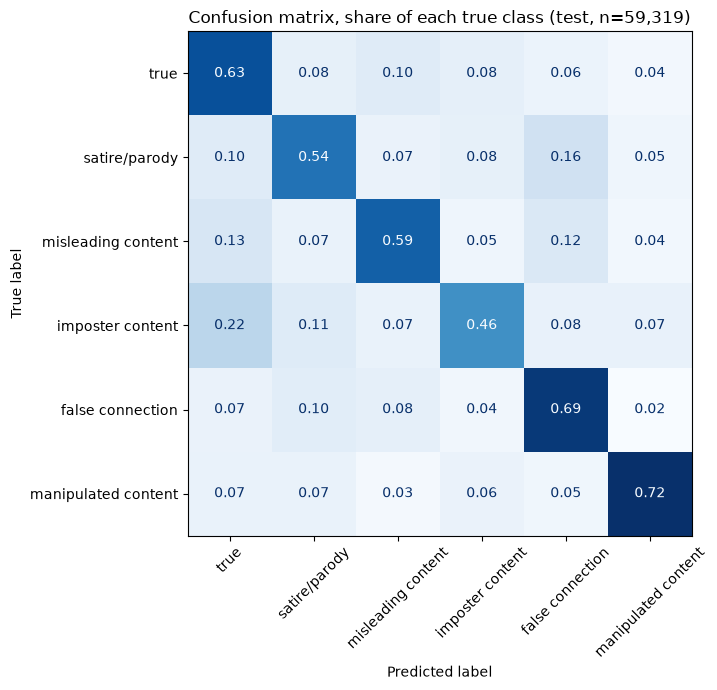

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test["6_way_label"], test["pred"], display_labels=CLASSES, normalize="true",  # eilutes procentais, kitaip mazos klases nesimatytu
                                        values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
ax.set_title(f"Confusion matrix, share of each true class (test, n={len(test):,})")
plt.tight_layout(); plt.savefig(FIG / "txt_confusion.png", dpi=120); plt.show()

## 5. Results by subreddit
Because each class is a group of subreddits, the recall of a class is really the average over its subreddits. This shows which communities the model recognises and which it mixes up.

In [10]:
test["correct"] = test["pred"] == test["6_way_label"]
wrong_as = test[~test["correct"]].groupby("subreddit")["pred"].agg(lambda p: CLASSES[p.mode()[0]])  # i kuria klase dazniausiai suklysta
by_sub = test.groupby("subreddit").agg(type=("type", "first"), posts=("correct", "size"), recall=("correct", "mean"))
by_sub["most often wrong as"] = wrong_as
by_sub.sort_values(["type", "recall"]).round(3)

,type,posts,recall,most often wrong as
subreddit,,,,
pic,true,619,0.423,satire/parody
neutralnews,true,791,0.555,satire/parody
photoshopbattles,true,5850,0.575,misleading content
usanews,true,631,0.580,satire/parody
usnews,true,613,0.604,satire/parody
nottheonion,true,3377,0.616,satire/parody
mildlyinteresting,true,9037,0.676,misleading content
upliftingnews,true,2589,0.722,satire/parody
satire,satire/parody,402,0.393,true


## 6. Most informative words per class
The model keeps one weight per word for each class. The words with the highest weight are the ones that pull a title most strongly towards that class.

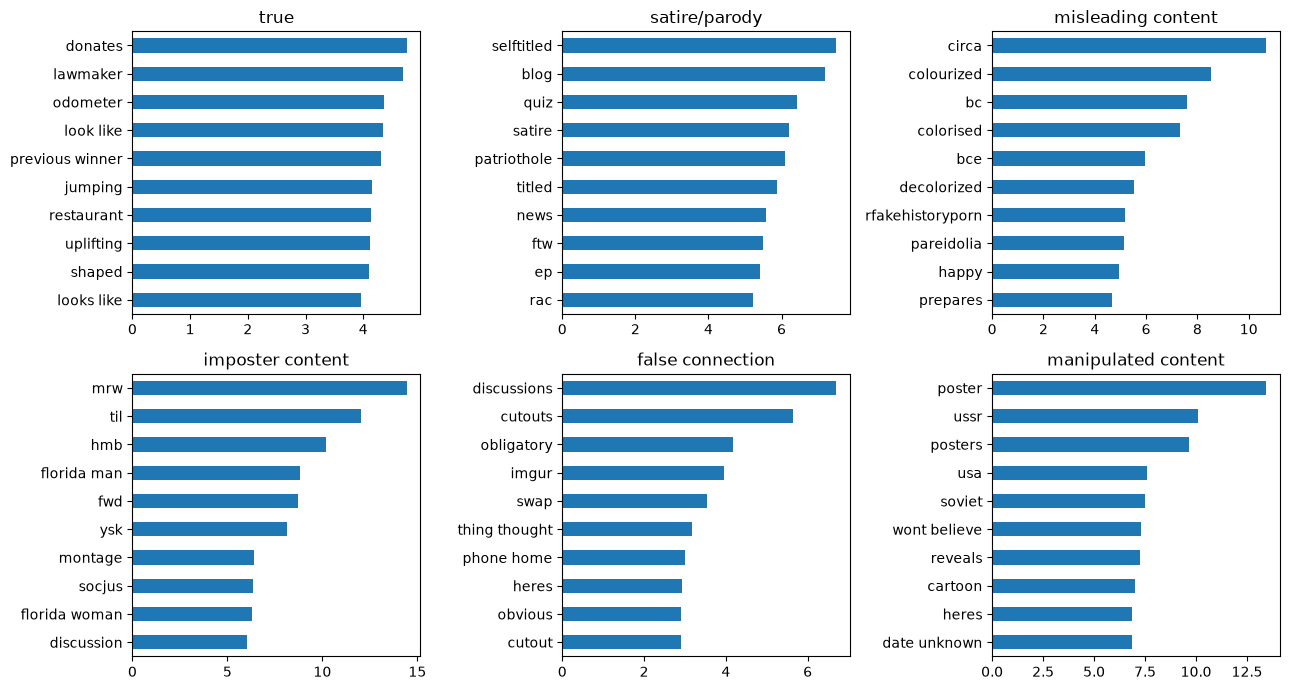

,true,satire/parody,misleading content,imposter content,false connection,manipulated content
0,donates,selftitled,circa,mrw,discussions,poster
1,lawmaker,blog,colourized,til,cutouts,ussr
2,odometer,quiz,bc,hmb,obligatory,posters
3,look like,satire,colorised,florida man,imgur,usa
4,previous winner,patriothole,bce,fwd,swap,soviet
5,jumping,titled,decolorized,ysk,thing thought,wont believe
6,restaurant,news,rfakehistoryporn,montage,phone home,reveals
7,uplifting,ftw,pareidolia,socjus,heres,cartoon
8,shaped,ep,happy,florida woman,obvious,heres
9,looks like,rac,prepares,discussion,cutout,date unknown


In [11]:
names = model[0].get_feature_names_out()
coef = pd.DataFrame(model[-1].coef_.T, index=names, columns=CLASSES)  # kiekvieno zodzio svoris kiekvienai klasei
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), CLASSES):
    coef[c].nlargest(10).sort_values().plot.barh(ax=ax, title=c)
plt.tight_layout(); plt.savefig(FIG / "txt_top_words.png", dpi=120); plt.show()
pd.DataFrame({c: coef[c].nlargest(10).index for c in CLASSES})

## 7. Examples
A random sample of test titles with the predicted and true class.

In [12]:
pd.set_option("display.max_colwidth", 80)
sample = test.sample(15, random_state=42)  # atsitiktiniai, kad matytume ir teisingus, ir klaidingus
pd.DataFrame({"title": sample["clean_title"], "subreddit": sample["subreddit"], "true class": sample["type"],
              "predicted": sample["pred"].map(dict(enumerate(CLASSES)))})

,title,subreddit,true class,predicted
22783,the pick,psbattle_artwork,false connection,false connection
53435,me jumping in a big leaf pile,photoshopbattles,true,true
36562,this lemon that has a face,mildlyinteresting,true,misleading content
2867,amazon is selling cck rings now,misleadingthumbnails,misleading content,true
46547,hot farmgirl mocking a cow,photoshopbattles,true,misleading content
1866,saddam hussein is executed,fakehistoryporn,misleading content,misleading content
54263,the one yellow kernel in my white corn,mildlyinteresting,true,true
44313,no more mr nice guy,psbattle_artwork,false connection,imposter content
45323,bill oreilly says same sex marriage foes are just a bunch of bible thumpers,nottheonion,true,true
37369,beer me,psbattle_artwork,false connection,true
